In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
m = pd.read_csv('vizs1_service - vizs1_service.csv')
w = pd.read_csv('vizs1_waterpoints - vizs1_waterpoints.csv')
p = pd.read_csv('vizs1_pressure - vizs1_pressure.csv')
c = pd.read_csv('vizs1_projects - vizs1_projects.csv')
print(m.shape, w.shape, p.shape, c.shape)

(72, 9) (300, 11) (432, 10) (120, 9)


In [8]:
m['month'] = pd.to_datetime(m['month'])
c['week_start'] = pd.to_datetime(
c['week_start'])
trend = m.groupby('month', as_index=False)[
'delivered_m3'].sum()
print(len(trend))
print(trend['delivered_m3']
.iloc[[0,-1]].tolist())

12
[331600, 356971]


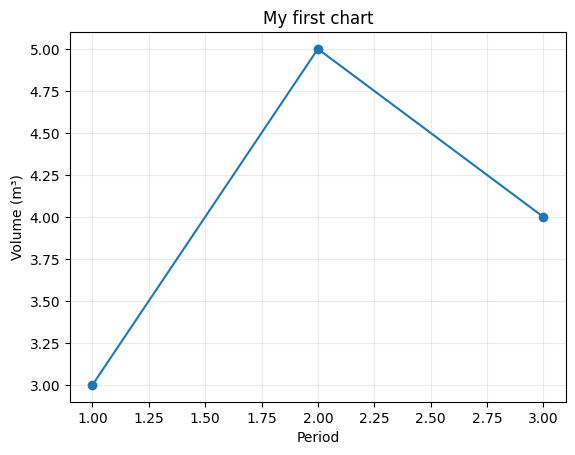

In [9]:
fig, ax = plt.subplots()
ax.plot([1, 2, 3], [3, 5, 4], marker='o')
ax.set(title='My first chart',
       xlabel='Period',
       ylabel='Volume (m³)')
ax.grid(alpha=0.25)
plt.show()

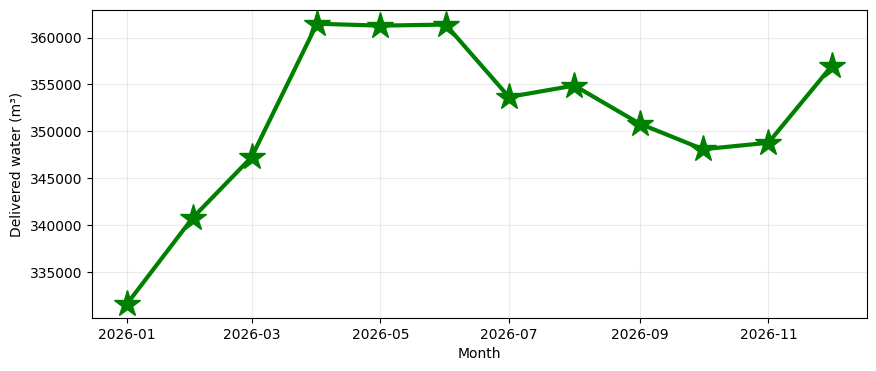

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(trend['month'],
trend['delivered_m3'],
marker='*', linewidth=3,color='green',markersize=20)
ax.set(xlabel='Month',ylabel='Delivered water (m³)')
ax.grid(alpha=0.25)
plt.show()

In [10]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

plt.style.use("ggplot")
sns.set_theme(style="whitegrid")

np.random.seed(42)
# Create sample water utility dataset

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

districts = [
    "Bole", "Yeka", "Arada", "Kirkos",
    "Gullele", "Nifas Silk", "Kolfe", "Akaki"
]

data = pd.DataFrame({
    "Month": months,
    "Production": [120, 125, 130, 128, 135, 140,
                   138, 145, 142, 150, 148, 155],
    "Distribution": [105, 108, 112, 110, 115, 120,
                     118, 125, 122, 130, 128, 135],
    "Revenue": [8, 8.5, 9, 8.8, 9.5, 10,
                9.8, 10.5, 10.2, 11, 10.8, 12],
    "Target": [95] * 12
})

district_data = pd.DataFrame({
    "District": districts,
    "Production": [150, 130, 110, 125, 100, 115, 90, 105],
    "Consumption": [120, 105, 90, 100, 82, 95, 70, 85],
    "Customers": [50000, 42000, 35000, 40000,
                  30000, 38000, 25000, 32000],
    "NRW": [20, 19, 18, 20, 18, 17, 22, 19]
})

# Generate individual customer consumption records
customer_consumption = np.random.normal(15, 5, 500)
customer_consumption = np.clip(customer_consumption, 1, 35)

# Generate water pressure readings
pressure = np.random.normal(45, 8, 100)
pressure = np.clip(pressure, 15, 70)

# Generate daily data
daily_dates = pd.date_range("2026-01-01", periods=30)

daily_data = pd.DataFrame({
    "Date": daily_dates,
    "Production": np.random.randint(100, 160, 30),
    "Distribution": np.random.randint(80, 140, 30)
})

# Generate operational financial data
financial_data = {
    "Opening Balance": 100,
    "Collections": 75,
    "Adjustments": -10,
    "Refunds": -5,
    "Closing Balance": 160
}

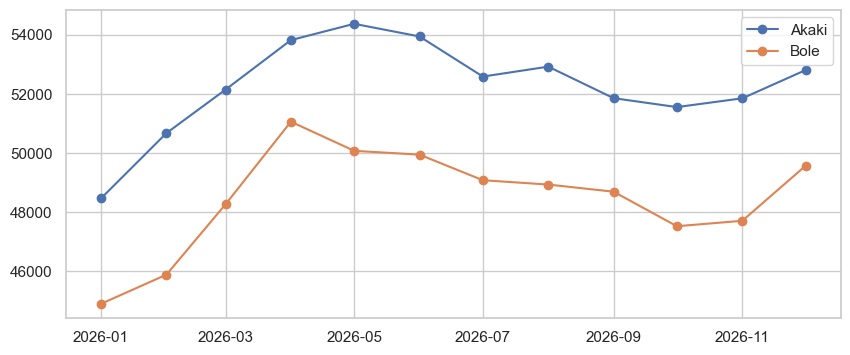

In [15]:
choice = m[m.district.isin(['Bole','Akaki'])]
fig, ax = plt.subplots(figsize=(10, 4))
for name, part in choice.groupby('district'):
    ax.plot(part['month'],
            part['delivered_m3'],
            label=name, marker='o')
ax.legend()
plt.show()

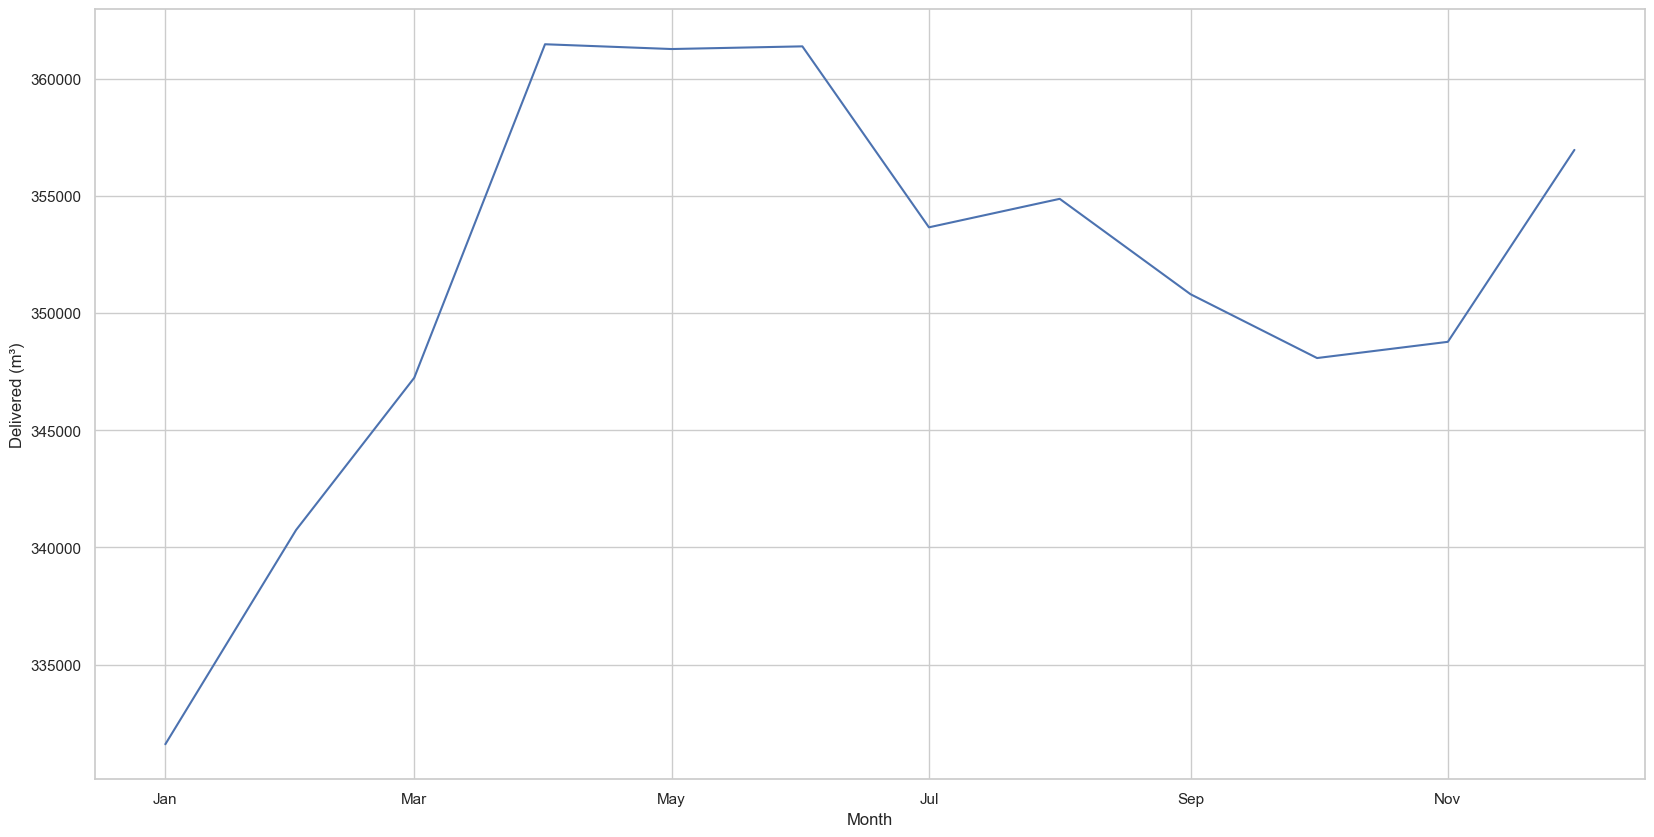

In [20]:
import matplotlib.dates as mdates
fig, ax = plt.subplots(figsize=(20, 10))
ax.plot(trend['month'],
trend['delivered_m3'])
ax.xaxis.set_major_formatter(
mdates.DateFormatter('%b'))
ax.set(xlabel='Month',ylabel='Delivered (m³)')
plt.show()

In [12]:
zone = m.groupby('district')[
'delivered_m3'].sum().sort_values()
print(zone.iloc[:3].to_dict())

{'Bole': 581580, 'Akaki': 626962, 'Kirkos': 669769}


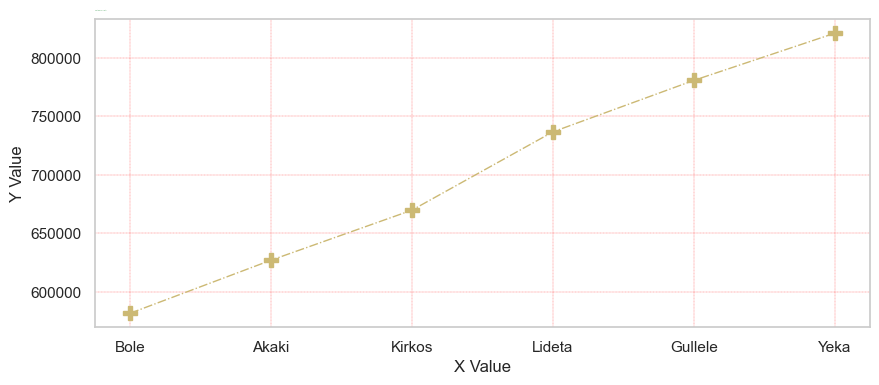

In [14]:
fig, ax = plt.subplots(figsize=(10, 4))
#ax.barh(zone.index, zone.values,color='red' )
#ax.bar(zone.index,zone.values)
#ax.set(xlabel='Delivered water (m³)',ylabel='District')
#ax.grid(axis='x', alpha=0.20)
ax.plot(zone.index, zone.values,marker='P',markersize=10,linestyle='dashdot',color='y',linewidth=1)#dotted dotted
plt.title(label="Customer Bill data",color='g',size=0.1,loc='left')
plt.xlabel("X Value")
plt.ylabel("Y Value")
plt.grid(color='red',linestyle='--',linewidth=0.2)
#plt.legend()
#plt.annotate(zone.index,zone.values)
ax.annotate("Peak", ('Bole', 6300000))
fig.savefig('aauv_s1_service_trend.png', dpi=200, bbox_inches='tight')

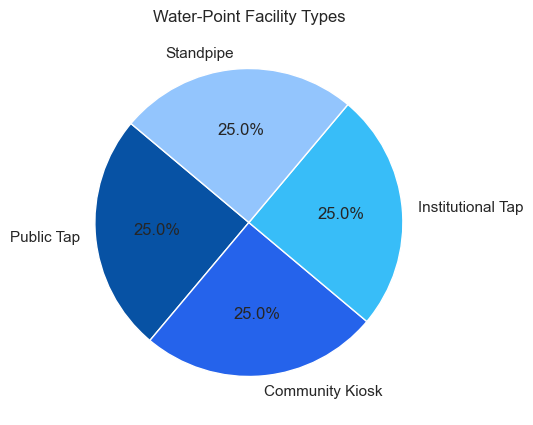

In [104]:
counts = w['point_type'].value_counts()
fig, ax = plt.subplots(figsize=(8, 5))
ax.pie(counts.values, labels=counts.index,
       autopct='%1.1f%%', startangle=140,
       colors=['#0752A4', '#2563EB', '#38BDF8', '#93C5FD'])
ax.set_title('Water-Point Facility Types')
explode=(0, 0, 0.08)
plt.show()

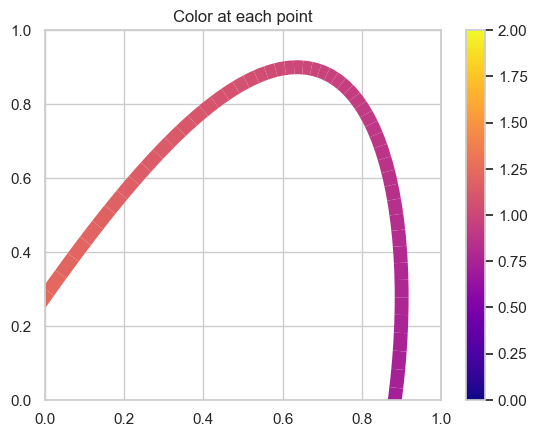

In [15]:
import warnings

import matplotlib.pyplot as plt
import numpy as np

from matplotlib.collections import LineCollection


def colored_line(x, y, c, ax=None, **lc_kwargs):
    """
    Plot a line with a color specified along the line by a third value.

    It does this by creating a collection of line segments. Each line segment is
    made up of two straight lines each connecting the current (x, y) point to the
    midpoints of the lines connecting the current point with its two neighbors.
    This creates a smooth line with no gaps between the line segments.

    Parameters
    ----------
    x, y : array-like
        The horizontal and vertical coordinates of the data points.
    c : array-like
        The color values, which should be the same size as x and y.
    ax : matplotlib.axes.Axes, optional
        The axes to plot on. If not provided, the current axes will be used.
    **lc_kwargs
        Any additional arguments to pass to matplotlib.collections.LineCollection
        constructor. This should not include the array keyword argument because
        that is set to the color argument. If provided, it will be overridden.

    Returns
    -------
    matplotlib.collections.LineCollection
        The generated line collection representing the colored line.
    """
    if "array" in lc_kwargs:
        warnings.warn(
            'The provided "array" keyword argument will be overridden',
            UserWarning,
            stacklevel=2,
        )

    xy = np.stack((x, y), axis=-1)
    xy_mid = np.concat(
        (xy[0, :][None, :], (xy[:-1, :] + xy[1:, :]) / 2, xy[-1, :][None, :]), axis=0
    )
    segments = np.stack((xy_mid[:-1, :], xy, xy_mid[1:, :]), axis=-2)
    # Note that
    # segments[0, :, :] is [xy[0, :], xy[0, :], (xy[0, :] + xy[1, :]) / 2]
    # segments[i, :, :] is [(xy[i - 1, :] + xy[i, :]) / 2, xy[i, :],
    #     (xy[i, :] + xy[i + 1, :]) / 2] if i not in {0, len(x) - 1}
    # segments[-1, :, :] is [(xy[-2, :] + xy[-1, :]) / 2, xy[-1, :], xy[-1, :]]

    lc_kwargs["array"] = c
    lc = LineCollection(segments, **lc_kwargs)

    # Plot the line collection to the axes
    ax = ax or plt.gca()
    ax.add_collection(lc)

    return lc


# -------------- Create and show plot --------------
# Some arbitrary function that gives x, y, and color values
t = np.linspace(-7.4, -0.5, 200)
x = 0.9 * np.sin(t)
y = 0.9 * np.cos(1.6 * t)
color = np.linspace(0, 2, t.size)

# Create a figure and plot the line on it
fig1, ax1 = plt.subplots()
lines = colored_line(x, y, color, ax1, linewidth=10, cmap="plasma")
fig1.colorbar(lines)  # add a color legend

ax1.set_title("Color at each point")

plt.show()

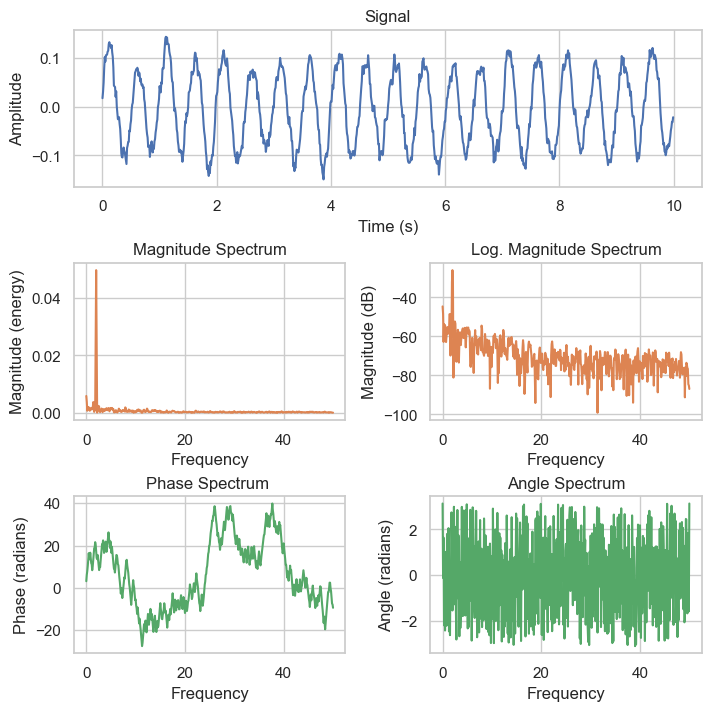

In [16]:
import matplotlib.pyplot as plt
import numpy as np

np.random.seed(0)

dt = 0.01  # sampling interval
Fs = 1 / dt  # sampling frequency
t = np.arange(0, 10, dt)

# generate noise:
nse = np.random.randn(len(t))
r = np.exp(-t / 0.05)
cnse = np.convolve(nse, r) * dt
cnse = cnse[:len(t)]

s = 0.1 * np.sin(4 * np.pi * t) + cnse  # the signal

fig = plt.figure(figsize=(7, 7), layout='constrained')
axs = fig.subplot_mosaic([["signal", "signal"],
                          ["magnitude", "log_magnitude"],
                          ["phase", "angle"]])

# plot time signal:
axs["signal"].set_title("Signal")
axs["signal"].plot(t, s, color='C0')
axs["signal"].set_xlabel("Time (s)")
axs["signal"].set_ylabel("Amplitude")

# plot different spectrum types:
axs["magnitude"].set_title("Magnitude Spectrum")
axs["magnitude"].magnitude_spectrum(s, Fs=Fs, color='C1')

axs["log_magnitude"].set_title("Log. Magnitude Spectrum")
axs["log_magnitude"].magnitude_spectrum(s, Fs=Fs, scale='dB', color='C1')

axs["phase"].set_title("Phase Spectrum ")
axs["phase"].phase_spectrum(s, Fs=Fs, color='C2')

axs["angle"].set_title("Angle Spectrum")
axs["angle"].angle_spectrum(s, Fs=Fs, color='C2')

plt.show()

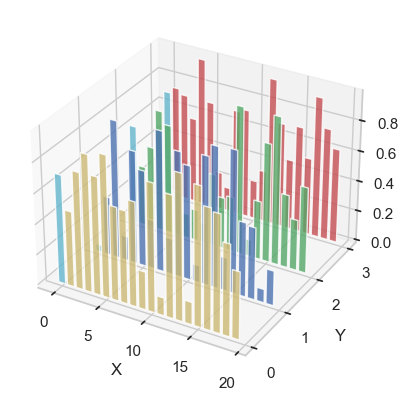

In [17]:
import matplotlib.pyplot as plt
import numpy as np

# Fixing random state for reproducibility
np.random.seed(19680801)


fig = plt.figure()
ax = fig.add_subplot(projection='3d')

colors = ['r', 'g', 'b', 'y']
yticks = [3, 2, 1, 0]
for c, k in zip(colors, yticks):
    # Generate the random data for the y=k 'layer'.
    xs = np.arange(20)
    ys = np.random.rand(20)

    # You can provide either a single color or an array with the same length as
    # xs and ys. To demonstrate this, we color the first bar of each set cyan.
    cs = [c] * len(xs)
    cs[0] = 'c'

    # Plot the bar graph given by xs and ys on the plane y=k with 80% opacity.
    ax.bar(xs, ys, zs=k, zdir='y', color=cs, alpha=0.8)

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

# On the y-axis let's only label the discrete values that we have data for.
ax.set_yticks(yticks)

plt.show()

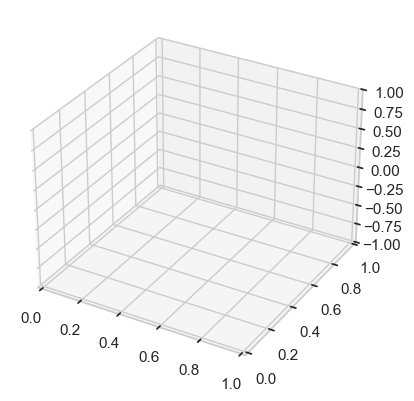

In [18]:
import time

import matplotlib.pyplot as plt
import numpy as np

from matplotlib import animation

FRAMES = 25
FPS = 25

fig = plt.figure()
ax = fig.add_subplot(projection='3d')

# Make the X, Y meshgrid.
xs = np.linspace(-1, 1, 50)
ys = np.linspace(-1, 1, 50)
X, Y = np.meshgrid(xs, ys)

# Set the z axis limits, so they aren't recalculated each frame.
ax.set_zlim(-1, 1)

# Begin plotting.
wframe = None
tstart = time.time()


def animate(i):
    global wframe
    # If a line collection is already there, remove it before drawing.
    if wframe:
        wframe.remove()
    # Generate data.
    phi = i / FRAMES * 2 * np.pi
    Z = np.cos(2 * np.pi * X + phi) * (1 - np.hypot(X, Y))
    # Plot the new wireframe.
    wframe = ax.plot_wireframe(X, Y, Z, rstride=2, cstride=2)
    if i == FRAMES - 1:  # Print FPS at the end of the loop.
        global tstart
        fps = FRAMES / (time.time() - tstart)
        print(f'Expected FPS: {FPS}; Average FPS: {fps}')
        tstart = time.time()


ani = animation.FuncAnimation(fig, animate, interval=1000 / FPS, frames=FRAMES)

plt.show()

AttributeError: 'tuple' object has no attribute 'wedges'

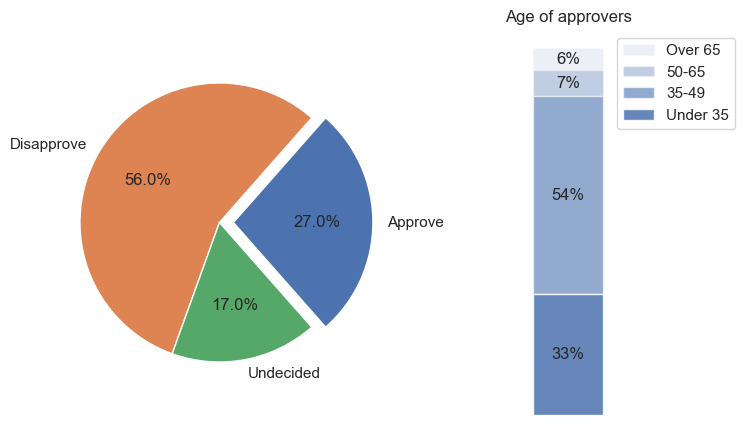

In [19]:
import matplotlib.pyplot as plt
import numpy as np

from matplotlib.patches import ConnectionPatch

# make figure and assign axis objects
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 5))
fig.subplots_adjust(wspace=0)

# pie chart parameters
overall_ratios = [.27, .56, .17]
labels = ['Approve', 'Disapprove', 'Undecided']
explode = [0.1, 0, 0]
# rotate so that first wedge is split by the x-axis
angle = -180 * overall_ratios[0]
pie = ax1.pie(overall_ratios, autopct='%1.1f%%', startangle=angle,
              labels=labels, explode=explode)

# bar chart parameters
age_ratios = [.33, .54, .07, .06]
age_labels = ['Under 35', '35-49', '50-65', 'Over 65']
bottom = 1
width = .2

# Adding from the top matches the legend.
for j, (height, label) in enumerate(reversed([*zip(age_ratios, age_labels)])):
    bottom -= height
    bc = ax2.bar(0, height, width, bottom=bottom, color='C0', label=label,
                 alpha=0.1 + 0.25 * j)
    ax2.bar_label(bc, labels=[f"{height:.0%}"], label_type='center')

ax2.set_title('Age of approvers')
ax2.legend()
ax2.axis('off')
ax2.set_xlim(- 2.5 * width, 2.5 * width)

# use ConnectionPatch to draw lines between the two plots
theta1, theta2 = pie.wedges[0].theta1, pie.wedges[0].theta2
center, r = pie.wedges[0].center, pie.wedges[0].r
bar_height = sum(age_ratios)

# draw top connecting line
x = r * np.cos(np.pi / 180 * theta2) + center[0]
y = r * np.sin(np.pi / 180 * theta2) + center[1]
con = ConnectionPatch(xyA=(-width / 2, bar_height), coordsA=ax2.transData,
                      xyB=(x, y), coordsB=ax1.transData)
con.set_color([0, 0, 0])
con.set_linewidth(4)
ax2.add_artist(con)

# draw bottom connecting line
x = r * np.cos(np.pi / 180 * theta1) + center[0]
y = r * np.sin(np.pi / 180 * theta1) + center[1]
con = ConnectionPatch(xyA=(-width / 2, 0), coordsA=ax2.transData,
                      xyB=(x, y), coordsB=ax1.transData)
con.set_color([0, 0, 0])
ax2.add_artist(con)
con.set_linewidth(4)

plt.show()

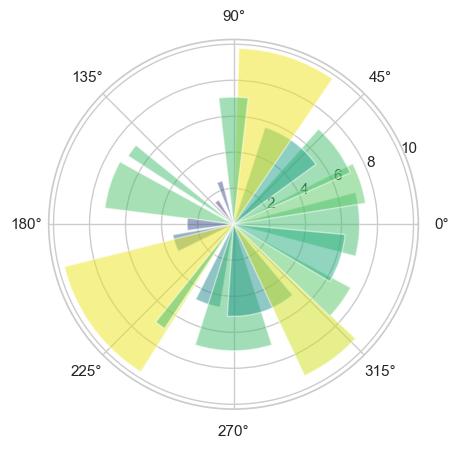

In [20]:
import matplotlib.pyplot as plt
import numpy as np

# Fixing random state for reproducibility
np.random.seed(19680801)

# Compute pie slices
N = 20
theta = np.linspace(0.0, 2 * np.pi, N, endpoint=False)
radii = 10 * np.random.rand(N)
width = np.pi / 4 * np.random.rand(N)
colors = plt.colormaps["viridis"](radii / 10.)

ax = plt.subplot(projection='polar')
ax.bar(theta, radii, width=width, bottom=0.0, color=colors, alpha=0.5)

plt.show()

C:\Users\Dagi\AppData\Roaming\Python\Python313\site-packages\matplotlib\animation.py:908: UserWarning: Animation was deleted without rendering anything. This is most likely not intended. To prevent deletion, assign the Animation to a variable, e.g. `anim`, that exists until you output the Animation using `plt.show()` or `anim.save()`.
  warnings.warn(


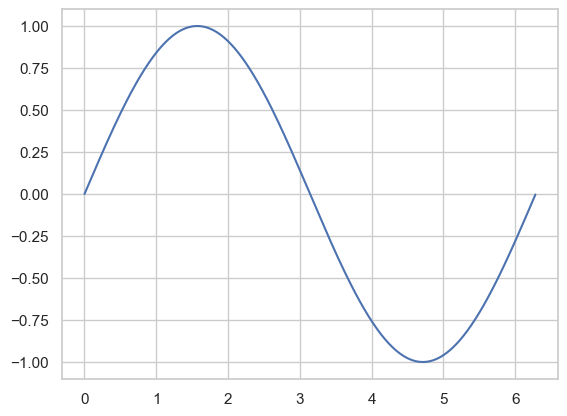

In [21]:
import matplotlib.pyplot as plt
import numpy as np

import matplotlib.animation as animation

fig, ax = plt.subplots()

x = np.arange(0, 2*np.pi, 0.01)
line, = ax.plot(x, np.sin(x))


def animate(i):
    line.set_ydata(np.sin(x + i / 50))  # update the data.
    return line,


ani = animation.FuncAnimation(
    fig, animate, interval=20, blit=True, save_count=50)

# To save the animation, use e.g.
#
# ani.save("movie.mp4")
#
# or
#
# writer = animation.FFMpegWriter(
#     fps=15, metadata=dict(artist='Me'), bitrate=1800)
# ani.save("movie.mp4", writer=writer)

plt.show()